In [1]:
# Mount Google Drive in Google Colab so Python can access the CSV file.
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
# Import the libraries used throughout the analysis and load the dataset.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path('/content/drive/MyDrive/ML_Project/sales_data.csv')

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. Check the file location or update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
print("Dataset loaded successfully.")


Dataset loaded successfully.


In [3]:
# Inspect sample records, dataset dimensions, columns, data types, and summary statistics.
print("First five records:")
display(df.head())

print("\nLast five records:")
display(df.tail())

print("\nDataset dimensions (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

# Identify numerical and categorical columns for EDA and preprocessing decisions.
numerical_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("\nNumerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)


First five records:


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59



Last five records:


,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
75995,2024-01-30,S005,P0016,Toys,North,233,63,0,29.80,5,Snowy,0,32.23,Winter,0,64
75996,2024-01-30,S005,P0017,Toys,North,137,115,141,42.92,5,Snowy,0,40.73,Winter,0,137
75997,2024-01-30,S005,P0018,Clothing,North,197,44,0,17.81,10,Snowy,0,19.41,Winter,0,68
75998,2024-01-30,S005,P0019,Furniture,North,125,58,0,151.72,0,Snowy,0,143.71,Winter,0,84
75999,2024-01-30,S005,P0020,Toys,North,126,63,59,25.78,10,Snowy,0,29.32,Winter,0,73



Dataset dimensions (rows, columns): (76000, 16)

Column names:
['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality', 'Epidemic', 'Demand']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                76000 non-null  object 
 1   Store ID            76000 non-null  object 
 2   Product ID          76000 non-null  object 
 3   Category            76000 non-null  object 
 4   Region              76000 non-null  object 
 5   Inventory Level     76000 non-null  int64  
 6   Units Sold          76000 non-null  int64  
 7   Units Ordered       76000 non-null  int64  
 8   Price               76000 non-null  float64
 9   Discount            76000 non-null  int6

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,76000,760,2024-01-30,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Store ID,76000,5,S001,15200,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product ID,76000,20,P0001,3800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,76000,5,Groceries,30400,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Region,76000,4,North,30400,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inventory Level,76000.0,NaN,NaN,NaN,301.062842,226.510161,0.0,136.0,227.0,408.0,2267.0
Units Sold,76000.0,NaN,NaN,NaN,88.827316,43.994525,0.0,58.0,84.0,114.0,426.0
Units Ordered,76000.0,NaN,NaN,NaN,89.090645,162.404627,0.0,0.0,0.0,121.0,1616.0
Price,76000.0,NaN,NaN,NaN,67.726028,39.377899,4.74,31.9975,64.5,95.83,228.03
Discount,76000.0,NaN,NaN,NaN,9.087039,7.475781,0.0,5.0,10.0,10.0,25.0



Numerical columns: ['Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Promotion', 'Competitor Pricing', 'Epidemic', 'Demand']
Categorical columns: ['Date', 'Store ID', 'Product ID', 'Category', 'Region', 'Weather Condition', 'Seasonality']


In [4]:
# Check missing values and exact duplicate rows before making any changes.
print("Missing values by column before cleaning:")
display(df.isna().sum().to_frame("Missing count"))

print("Exact duplicate rows:", df.duplicated().sum())

# Remove exact duplicate records so repeated rows do not influence the analysis twice.
df = df.drop_duplicates().copy()

# Parse dates if the Date column exists; invalid dates are converted to NaT and counted.
if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    print("Missing/invalid dates after conversion:", df["Date"].isna().sum())

# Impute missing numerical values with the median and categorical values with the mode.
# This is only applied when missing values actually exist.
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

for col in numeric_cols:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    if df[col].isna().any():
        modes = df[col].mode(dropna=True)
        fill_value = modes.iloc[0] if not modes.empty else "Unknown"
        df[col] = df[col].fillna(fill_value)

print("\nMissing values after basic imputation:")
display(df.isna().sum().to_frame("Missing count"))

# Check for impossible values that may indicate data-entry issues.
for col in ["Inventory Level", "Units Sold", "Units Ordered", "Price", "Demand"]:
    if col in df.columns:
        print(f"Negative values in {col}:", (df[col] < 0).sum())

if "Discount" in df.columns:
    print("Discount values outside 0–100:", ((df["Discount"] < 0) | (df["Discount"] > 100)).sum())


Missing values by column before cleaning:


,Missing count
Date,0
Store ID,0
Product ID,0
Category,0
Region,0
Inventory Level,0
Units Sold,0
Units Ordered,0
Price,0
Discount,0


Exact duplicate rows: 0
Missing/invalid dates after conversion: 0

Missing values after basic imputation:


,Missing count
Date,0
Store ID,0
Product ID,0
Category,0
Region,0
Inventory Level,0
Units Sold,0
Units Ordered,0
Price,0
Discount,0


Negative values in Inventory Level: 0
Negative values in Units Sold: 0
Negative values in Units Ordered: 0
Negative values in Price: 0
Negative values in Demand: 0
Discount values outside 0–100: 0


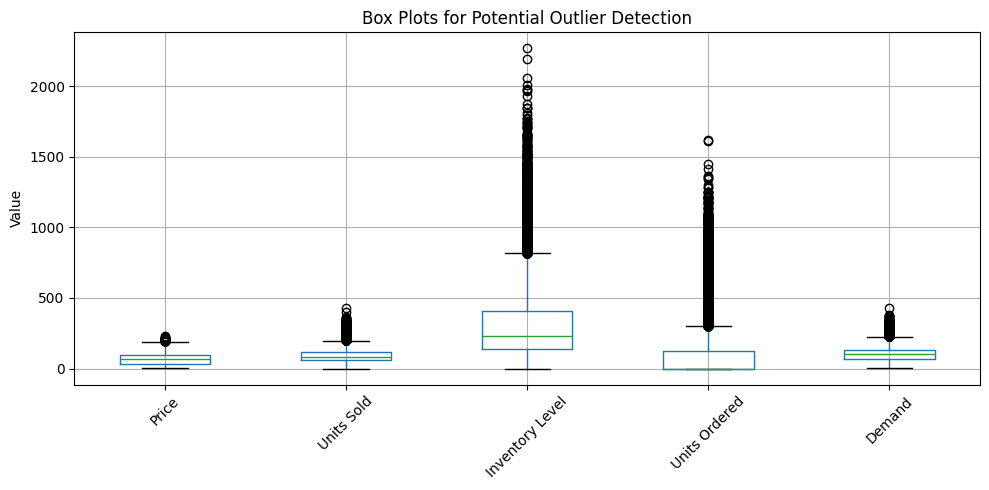

,count,mean,std,min,25%,50%,75%,max
Price,76000.0,67.726028,39.377899,4.74,31.9975,64.5,95.83,228.03
Units Sold,76000.0,88.827316,43.994525,0.00,58.0000,84.0,114.00,426.00
Inventory Level,76000.0,301.062842,226.510161,0.00,136.0000,227.0,408.00,2267.00
Units Ordered,76000.0,89.090645,162.404627,0.00,0.0000,0.0,121.00,1616.00
Demand,76000.0,104.317158,46.964801,4.00,71.0000,100.0,133.00,430.00


,Product ID,Store ID,Inventory Level,Units Sold,Demand
22285,P0006,S005,2267,72,96
22385,P0006,S005,2195,136,133
22485,P0006,S005,2059,85,129
36569,P0010,S004,2007,75,97
57452,P0013,S003,1977,133,163


In [5]:
# Use box plots to flag potential outliers in key numeric business variables.
# Box plots identify unusual values; they do not prove that a record is incorrect.
outlier_cols = [
    col for col in ["Price", "Units Sold", "Inventory Level", "Units Ordered", "Demand"]
    if col in df.columns
]

df[outlier_cols].boxplot(figsize=(10, 5))
plt.title("Box Plots for Potential Outlier Detection")
plt.ylabel("Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("outlier_boxplots.png", dpi=200, bbox_inches="tight")
plt.show()

# Review descriptive statistics and the largest inventory observations as a sanity check.
display(df[outlier_cols].describe().T)
if "Inventory Level" in df.columns:
    display(df.nlargest(5, "Inventory Level")[
        [c for c in ["Product ID", "Store ID", "Inventory Level", "Units Sold", "Demand"] if c in df.columns]
    ])


In [6]:
# Define the numerical variables used to compare product-level inventory and demand profiles.
# Product ID is an identifier, so it must not be treated as a numeric measurement.
feature_cols = [
    "Inventory Level", "Units Sold", "Units Ordered",
    "Price", "Discount", "Demand"
]
required_cols = ["Product ID"] + feature_cols
missing_required = [col for col in required_cols if col not in df.columns]
if missing_required:
    raise ValueError(f"Required dataset columns are missing: {missing_required}")

print("Clustering features:", feature_cols)
print("Categorical columns excluded from distance calculations:", categorical_cols)


Clustering features: ['Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Demand']
Categorical columns excluded from distance calculations: ['Store ID', 'Product ID', 'Category', 'Region', 'Weather Condition', 'Seasonality']


In [7]:
# Aggregate observations by Product ID so each product is represented by its average profile.
# The categorical product category is kept separately for display and interpretation only.
product_df = (
    df.groupby("Product ID", as_index=False)[feature_cols]
      .mean()
)

if "Category" in df.columns:
    product_categories = (
        df.groupby("Product ID")["Category"]
          .agg(lambda values: values.mode().iloc[0] if not values.mode().empty else "Unknown")
    )
else:
    product_categories = pd.Series("Unknown", index=product_df["Product ID"])

print("Original cleaned dataset shape:", df.shape)
print("Product-level dataset shape:", product_df.shape)
display(product_df.head())


Original cleaned dataset shape: (76000, 16)
Product-level dataset shape: (20, 7)


,Product ID,Inventory Level,Units Sold,Units Ordered,Price,Discount,Demand
0,P0001,331.758684,93.898421,94.238947,37.220403,9.176316,109.591316
1,P0002,285.830789,94.567105,94.850526,42.719934,9.084211,112.066579
2,P0003,310.263684,89.876579,90.192632,76.364639,9.076316,103.995263
3,P0004,320.350000,99.375526,99.642632,45.307184,9.148684,115.396053
4,P0005,392.904211,92.569737,93.116053,50.747358,9.157895,107.520526


In [8]:
# Standardize only the six numerical clustering features; do not scale Product ID.
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_features = scaler.fit_transform(product_df[feature_cols])

print("Scaled feature matrix shape:", scaled_features.shape)
print("Number of products used for clustering:", len(product_df))


Scaled feature matrix shape: (20, 6)
Number of products used for clustering: 20


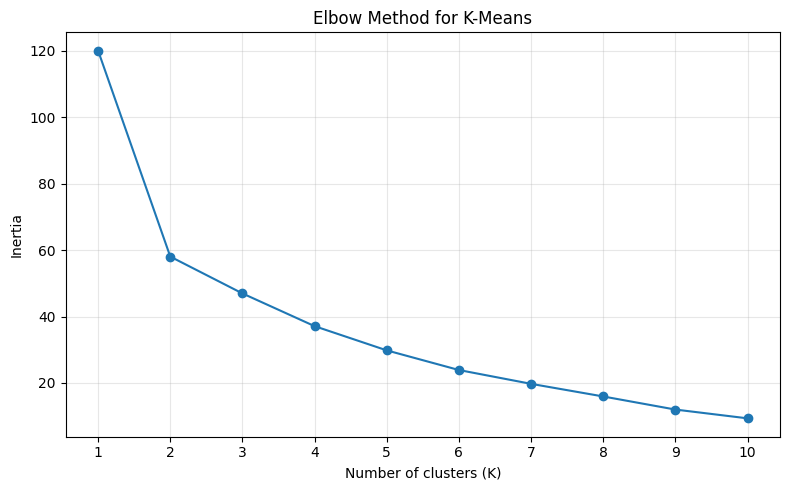

In [9]:
# Calculate within-cluster sum of squares (inertia) for K=1 through K=10.
from sklearn.cluster import KMeans

max_k = min(10, len(product_df) - 1)
k_values = list(range(1, max_k + 1))
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(scaled_features)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.title("Elbow Method for K-Means")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("elbow_plot.png", dpi=200, bbox_inches="tight")
plt.show()


In [10]:
# Fit and evaluate K-Means for K=2, 3, and 4 (when the dataset has enough products).
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.cluster import AgglomerativeClustering

comparison_rows = []
kmeans_models = {}
kmeans_labels_by_k = {}

for k in [2, 3, 4]:
    if k >= len(product_df):
        continue
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(scaled_features)
    kmeans_models[k] = model
    kmeans_labels_by_k[k] = labels
    comparison_rows.append({
        "Model": f"K-Means (K={k})",
        "Clusters": k,
        "Silhouette Score": silhouette_score(scaled_features, labels),
        "Davies-Bouldin Index": davies_bouldin_score(scaled_features, labels)
    })

# Fit Hierarchical/Agglomerative clustering with two clusters for comparison.
hierarchical_model = AgglomerativeClustering(n_clusters=2, linkage="ward")
hierarchical_labels = hierarchical_model.fit_predict(scaled_features)
comparison_rows.append({
    "Model": "Hierarchical (K=2)",
    "Clusters": 2,
    "Silhouette Score": silhouette_score(scaled_features, hierarchical_labels),
    "Davies-Bouldin Index": davies_bouldin_score(scaled_features, hierarchical_labels)
})

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df.round(4))

# Select K=2 K-Means as the simple, interpretable solution used for the remaining
# product profiles. This is a choice based on the measured metrics and business simplicity,
# not a claim that it wins every metric.
selected_k = 2
kmeans = kmeans_models[selected_k]
product_df["KMeans_Cluster"] = kmeans_labels_by_k[selected_k]
product_df["Hierarchical_Cluster"] = hierarchical_labels

print("Selected interpretation model: K-Means with K =", selected_k)


,Model,Clusters,Silhouette Score,Davies-Bouldin Index
0,K-Means (K=2),2,0.3884,0.9260
1,K-Means (K=3),3,0.2710,1.2184
2,K-Means (K=4),4,0.2649,0.9523
3,Hierarchical (K=2),2,0.3716,0.9332


Selected interpretation model: K-Means with K = 2


In [11]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

product_df["KMeans_Cluster"] = kmeans.fit_predict(scaled_features)

display(product_df)

,Product ID,Inventory Level,Units Sold,Units Ordered,Price,Discount,Demand,KMeans_Cluster,Hierarchical_Cluster
0,P0001,331.758684,93.898421,94.238947,37.220403,9.176316,109.591316,1,1
1,P0002,285.830789,94.567105,94.850526,42.719934,9.084211,112.066579,1,1
2,P0003,310.263684,89.876579,90.192632,76.364639,9.076316,103.995263,1,0
3,P0004,320.350000,99.375526,99.642632,45.307184,9.148684,115.396053,1,1
4,P0005,392.904211,92.569737,93.116053,50.747358,9.157895,107.520526,1,1
5,P0006,283.058421,90.681316,90.836053,46.914603,9.114474,107.722368,1,1
6,P0007,466.860000,99.923421,100.556842,35.674368,9.130263,115.023421,1,1
7,P0008,151.431316,85.083421,85.005000,67.067661,9.034211,104.352105,0,0
8,P0009,272.303684,99.150263,99.238158,83.047739,8.985526,118.506316,1,1
9,P0010,310.549474,94.026053,94.227105,66.468400,9.164474,111.069474,1,1


In [12]:
# Summarize the average feature values and product counts within each K-Means cluster.
cluster_summary = product_df.groupby("KMeans_Cluster").agg(
    Product_Count=("Product ID", "count"),
    **{col: (col, "mean") for col in feature_cols}
).round(2)

display(cluster_summary)

# Display which Product IDs belong to each cluster for traceability.
display(
    product_df[["Product ID", "KMeans_Cluster", "Hierarchical_Cluster"]]
    .sort_values(["KMeans_Cluster", "Product ID"])
    .reset_index(drop=True)
)


,Product_Count,Inventory Level,Units Sold,Units Ordered,Price,Discount,Demand
KMeans_Cluster,,,,,,,
0,9,258.19,81.67,81.84,84.67,9.05,96.33
1,11,336.14,94.68,95.02,53.87,9.11,110.86


,Product ID,KMeans_Cluster,Hierarchical_Cluster
0,P0008,0,0
1,P0011,0,0
2,P0012,0,0
3,P0014,0,0
4,P0016,0,0
5,P0017,0,0
6,P0018,0,0
7,P0019,0,0
8,P0020,0,0
9,P0001,1,1


Variance explained by the two components: 0.8339


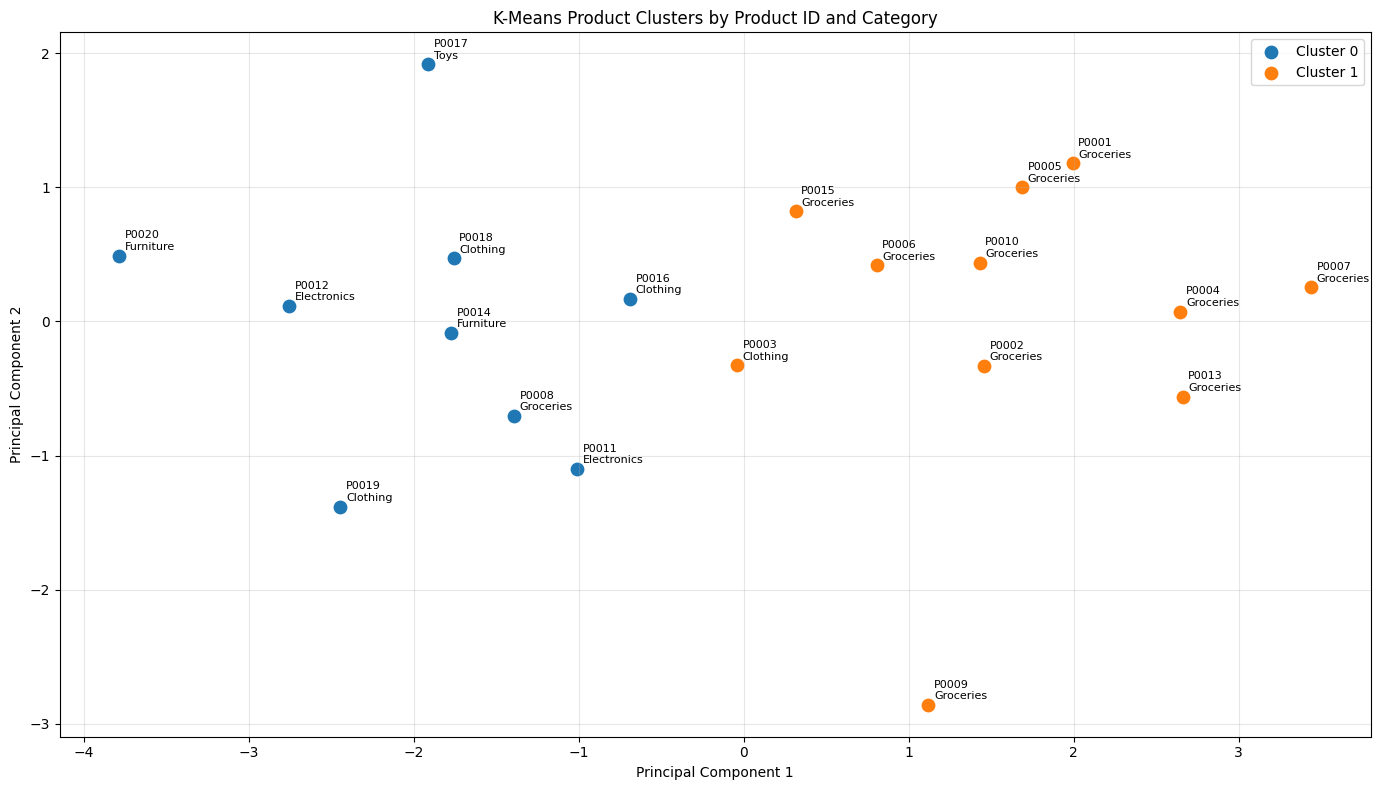

In [13]:
# Reduce the six standardized features to two principal components for visualization only.
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
reduced_features = pca.fit_transform(scaled_features)
print("Variance explained by the two components:", round(pca.explained_variance_ratio_.sum(), 4))

plt.figure(figsize=(14, 8))
for cluster in sorted(product_df["KMeans_Cluster"].unique()):
    mask = (product_df["KMeans_Cluster"] == cluster).to_numpy()
    plt.scatter(
        reduced_features[mask, 0],
        reduced_features[mask, 1],
        label=f"Cluster {cluster}",
        s=80
    )

for i, product_id in enumerate(product_df["Product ID"]):
    category = product_categories.get(product_id, "Unknown")
    plt.annotate(
        f"{product_id}\n{category}",
        (reduced_features[i, 0], reduced_features[i, 1]),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("K-Means Product Clusters by Product ID and Category")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("pca_cluster_plot.png", dpi=200, bbox_inches="tight")
plt.show()


In [14]:
display(product_df[["Product ID", "KMeans_Cluster"]].sort_values("KMeans_Cluster"))

,Product ID,KMeans_Cluster
7,P0008,0
15,P0016,0
10,P0011,0
11,P0012,0
13,P0014,0
18,P0019,0
17,P0018,0
16,P0017,0
19,P0020,0
5,P0006,1


In [15]:
for cluster in sorted(product_df["KMeans_Cluster"].unique()):
    data = product_df[product_df["KMeans_Cluster"] == cluster]

    print(f"\nCluster {cluster}")
    print("Number of products:", len(data))
    print("Average inventory:", round(data["Inventory Level"].mean(), 2))
    print("Average demand:", round(data["Demand"].mean(), 2))
    print("Average units sold:", round(data["Units Sold"].mean(), 2))


Cluster 0
Number of products: 9
Average inventory: 258.19
Average demand: 96.33
Average units sold: 81.67

Cluster 1
Number of products: 11
Average inventory: 336.14
Average demand: 110.86
Average units sold: 94.68


In [16]:
inventory_demand_summary = product_df.groupby("KMeans_Cluster").agg({
    "Inventory Level": "mean",
    "Demand": "mean"
})

inventory_demand_summary["Inventory-Demand Difference"] = (
    inventory_demand_summary["Inventory Level"]
    - inventory_demand_summary["Demand"]
)

display(inventory_demand_summary.round(2))

,Inventory Level,Demand,Inventory-Demand Difference
KMeans_Cluster,,,
0,258.19,96.33,161.87
1,336.14,110.86,225.28


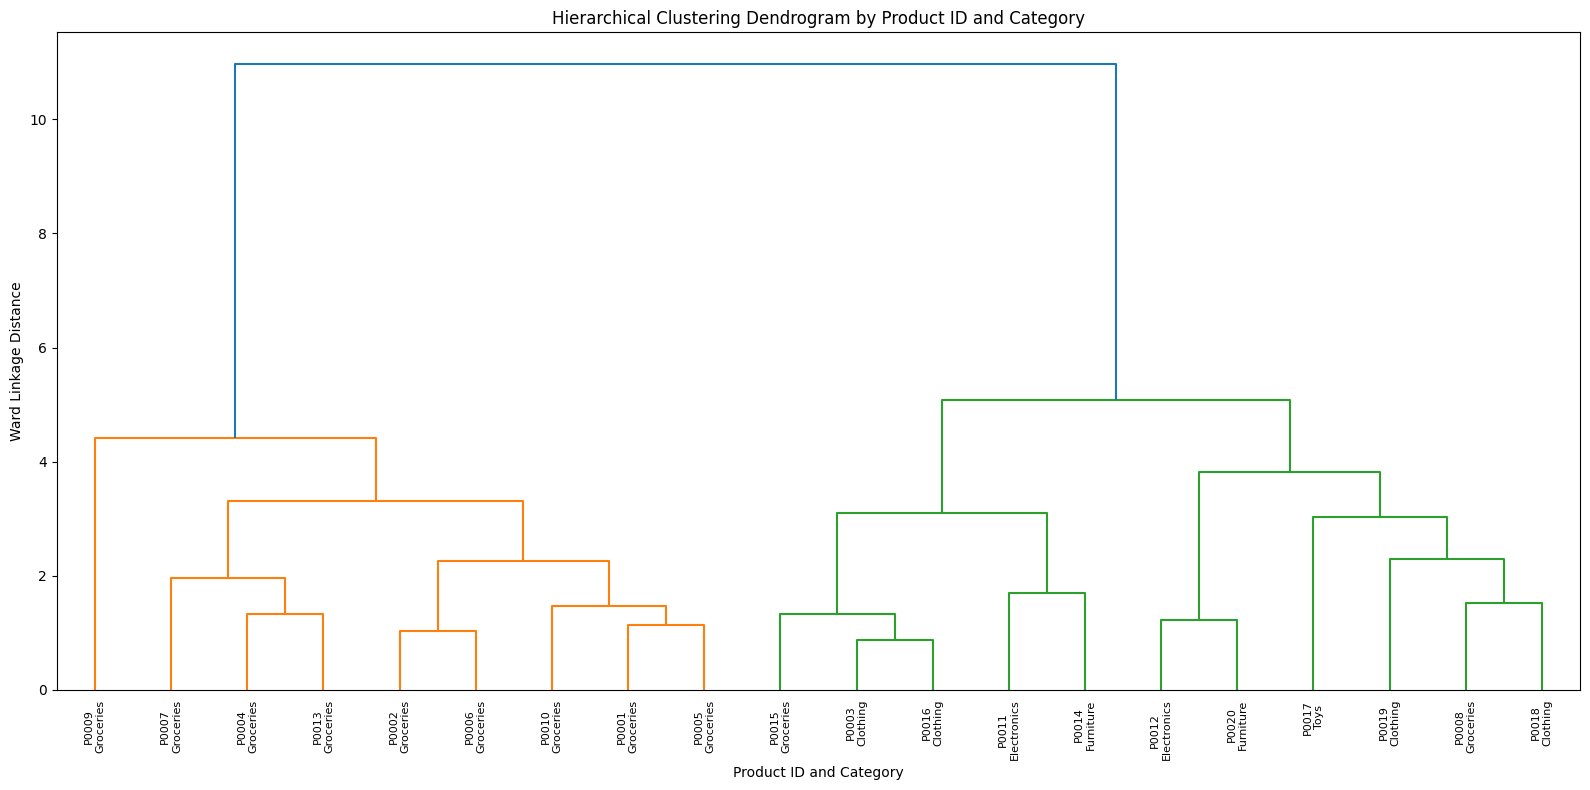

In [17]:
# Build a Ward-linkage dendrogram using the same standardized numeric features.
from scipy.cluster.hierarchy import dendrogram, linkage

linked = linkage(scaled_features, method="ward")
dendrogram_labels = [
    f"{pid}\n{product_categories.get(pid, 'Unknown')}"
    for pid in product_df["Product ID"]
]

plt.figure(figsize=(16, 8))
dendrogram(
    linked,
    labels=dendrogram_labels,
    leaf_rotation=90,
    leaf_font_size=8
)
plt.title("Hierarchical Clustering Dendrogram by Product ID and Category")
plt.xlabel("Product ID and Category")
plt.ylabel("Ward Linkage Distance")
plt.tight_layout()
plt.savefig("hierarchical_dendrogram.png", dpi=200, bbox_inches="tight")
plt.show()


,Inventory Level,Units Sold,Units Ordered,Demand
Category,,,,
Clothing,282.10,94.64,94.90,112.62
Electronics,289.26,83.04,83.34,97.48
Furniture,250.07,64.38,64.53,73.58
Groceries,360.31,102.87,103.23,120.98
Toys,229.11,78.45,78.55,92.61


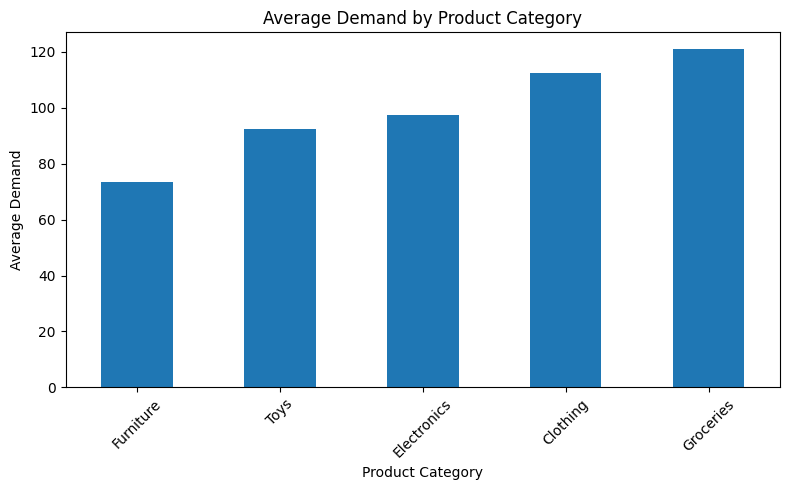

In [18]:
# Calculate category-level averages for inventory, sales, orders, and demand.
category_summary = df.groupby("Category").agg({
    "Inventory Level": "mean",
    "Units Sold": "mean",
    "Units Ordered": "mean",
    "Demand": "mean"
}).round(2)

display(category_summary)

# Plot average demand by category and save the figure for separate submission.
category_summary["Demand"].sort_values().plot(kind="bar", figsize=(8, 5))
plt.title("Average Demand by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Average Demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("category_average_demand.png", dpi=200, bbox_inches="tight")
plt.show()


In [19]:
# Compare mean inventory and demand within each cluster.
inventory_demand_summary = product_df.groupby("KMeans_Cluster").agg({
    "Inventory Level": "mean",
    "Demand": "mean"
})
inventory_demand_summary["Inventory-Demand Difference"] = (
    inventory_demand_summary["Inventory Level"] - inventory_demand_summary["Demand"]
)
display(inventory_demand_summary.round(2))


,Inventory Level,Demand,Inventory-Demand Difference
KMeans_Cluster,,,
0,258.19,96.33,161.87
1,336.14,110.86,225.28
